# Effect of Feature Standardization on Gradient-Descent Convergence in Logistic Regression

## 1. Research Question

## 2. Dataset

## 3. Data Preparation

## 4. Raw and Standardized Features

## 5. Experimental Setup

## 6. Six Experimental Runs

## 7. Experimental Results

## 8. Loss Curves

## 9. Convergence Speed

## 10. F1-Score Comparison

## 11. Interpretation

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

In [2]:
PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: d:\churnlab


In [3]:
from src.preprocessing import *
from src.logistic_regression import LogisticRegression
from src.metrics import *

In [4]:
DATA_PATH = PROJECT_ROOT / "data" / "dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (500, 6)


In [5]:
df.head()

,age,tenure,monthly_charges,support_calls,contract_type,churn
0,56,22,88.46,6,month-to-month,1
1,69,65,28.79,9,one-year,0
2,46,26,33.88,1,month-to-month,0
3,32,1,20.27,1,two-year,0
4,60,16,31.67,3,month-to-month,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              500 non-null    int64  
 1   tenure           500 non-null    int64  
 2   monthly_charges  500 non-null    float64
 3   support_calls    500 non-null    int64  
 4   contract_type    500 non-null    str    
 5   churn            500 non-null    int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 28.9 KB


In [7]:
df.describe(include="all")

,age,tenure,monthly_charges,support_calls,contract_type,churn
count,500.000000,500.000000,500.000000,500.000000,500,500.000000
unique,NaN,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,NaN,month-to-month,NaN
freq,NaN,NaN,NaN,NaN,244,NaN
mean,49.910000,34.200000,71.257280,4.496000,NaN,0.380000
std,18.221909,21.010924,28.977566,2.906351,NaN,0.485873
min,18.000000,0.000000,20.020000,0.000000,NaN,0.000000
25%,35.000000,16.000000,46.282500,2.000000,NaN,0.000000
50%,50.000000,33.000000,72.375000,5.000000,NaN,0.000000
75%,66.000000,53.000000,96.677500,7.000000,NaN,1.000000


## 3. Data Preparation

We use the existing ChurnLab preprocessing pipeline to prepare the dataset.
No new preprocessing implementation is introduced for this experiment.

In [8]:
import inspect
import src.preprocessing as preprocessing

print(inspect.getsource(preprocessing))

import pandas as pd
import numpy as np

def load_data(path):
    """
    Load the churn dataset from a CSV file.

    Parameters
    ----------
    path : str
        Path to the dataset CSV file.

    Returns
    -------
    pandas.DataFrame
        Loaded dataset.
    """
    return pd.read_csv(path)





def train_test_split(X, y, test_size=0.2, random_state=42):
    rng = np.random.default_rng(random_state)

    n_samples = X.shape[0]

    indices = np.arange(n_samples)
    rng.shuffle(indices)

    n_test = int(n_samples * test_size)

    test_indices = indices[:n_test]
    train_indices = indices[n_test:]

    # Select rows using their integer positions
    X_train = X.iloc[train_indices]
    X_test = X.iloc[test_indices]

    # y is a Pandas Series, so .iloc works here too
    y_train = y.iloc[train_indices]
    y_test = y.iloc[test_indices]

    return X_train, X_test, y_train, y_test




def encode_categorical(X_train, X_test):
    categories = ["month-to-month", "one-year", "

In [9]:
df = load_data(DATA_PATH)

X = df.drop("churn", axis=1)
y = df["churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

X shape: (500, 5)
y shape: (500,)

Target distribution:
churn
0    310
1    190
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 400
Testing samples: 100


In [11]:
X_train_encoded, X_test_encoded = encode_categorical(
    X_train,
    X_test
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (400, 7)
Encoded testing shape: (100, 7)


In [12]:
X_train_num = X_train_encoded.to_numpy(dtype=float)
X_test_num = X_test_encoded.to_numpy(dtype=float)

y_train_num = y_train.to_numpy(dtype=int)
y_test_num = y_test.to_numpy(dtype=int)

print("X_train:", X_train_num.shape)
print("X_test:", X_test_num.shape)
print("y_train:", y_train_num.shape)
print("y_test:", y_test_num.shape)

X_train: (400, 7)
X_test: (100, 7)
y_train: (400,)
y_test: (100,)


In [13]:
print("NaNs in encoded training features:", np.isnan(X_train_num).sum())
print("NaNs in encoded test features:", np.isnan(X_test_num).sum())

NaNs in encoded training features: 0
NaNs in encoded test features: 0


### 4.1 Raw Features

The raw experimental condition uses the processed numerical features without feature standardization.

In [14]:
X_train_raw = X_train_num.copy()
X_test_raw = X_test_num.copy()

print("Raw training shape:", X_train_raw.shape)
print("Raw testing shape:", X_test_raw.shape)

Raw training shape: (400, 7)
Raw testing shape: (100, 7)


### 4.2 Standardized Features

In [18]:
train_mean = calculate_mean(X_train_num)
train_std = calculate_std(X_train_num, train_mean)

X_train_standardized = standardize(
    X_train_num,
    train_mean,
    train_std
)

X_test_standardized = standardize(
    X_test_num,
    train_mean,
    train_std
)

print("Standardized training shape:", X_train_standardized.shape)
print("Standardized testing shape:", X_test_standardized.shape)

Standardized training shape: (400, 7)
Standardized testing shape: (100, 7)


In [19]:
print("Raw feature means:")
print(np.mean(X_train_raw, axis=0))

print("\nStandardized feature means:")
print(np.mean(X_train_standardized, axis=0))

print("\nStandardized feature standard deviations:")
print(np.std(X_train_standardized, axis=0))

Raw feature means:
[49.655    33.62     70.807175  4.3725    0.4775    0.33      0.1925  ]

Standardized feature means:
[-6.21724894e-17  1.27675648e-16 -3.55271368e-17  1.50990331e-16
 -8.88178420e-18 -9.76996262e-17  0.00000000e+00]

Standardized feature standard deviations:
[1. 1. 1. 1. 1. 1. 1.]


## 5. Experimental Setup

The same LogisticRegression implementation from ChurnLab is used for all experimental conditions. The model implementation is not modified. Only feature representation (raw or standardized) and learning rate are varied.

In [20]:
import inspect

print(inspect.signature(LogisticRegression))
print()
print(inspect.signature(LogisticRegression.fit))

(learning_rate=0.01, epochs=1000)

(self, X, y)


In [21]:
print(inspect.getsource(LogisticRegression))

class LogisticRegression:

    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.loss_history = []

    def binary_cross_entropy(self, y_true, probabilities):
        epsilon = 1e-15

        probabilities = np.clip(probabilities, epsilon, 1 - epsilon) ##Keep every probability between epsilon and 1-epsilon

        loss = -np.mean(
            y_true * np.log(probabilities) + (1 - y_true) * np.log(1 - probabilities)
        )

        return loss

    def calculate_gradients(self, X, y, probabilities):
        errors = probabilities - y

        weight_gradient = np.dot(X.T, errors) / len(y)
        bias_gradient = np.mean(errors)

        return weight_gradient, bias_gradient

    def update_parameters(self, weight_gradient, bias_gradient):
        self.weights -= self.learning_rate * weight_gradient
        self.bias -= self.learning_rate * bias_gr

## 6. Six Experimental Runs

### 6.1 Raw Features — Learning Rate 0.001

In [22]:
model_raw_001 = LogisticRegression(
    learning_rate=0.001,
    epochs=1000
)

In [23]:
model_raw_001.fit(
    X_train_raw,
    y_train_num
)

Epoch 1: Loss = 0.6931471805599452
Epoch 2: Loss = 0.6854078060381121
Epoch 3: Loss = 0.6720647701003997
Epoch 4: Loss = 0.6757076267605823
Epoch 5: Loss = 0.6618933352233068
Epoch 6: Loss = 0.669838968044931
Epoch 7: Loss = 0.6520547539108356
Epoch 8: Loss = 0.6590296594505933
Epoch 9: Loss = 0.6400168067641536
Epoch 10: Loss = 0.6440967180104209
Epoch 11: Loss = 0.6272009990620451
Epoch 12: Loss = 0.6285409267390925
Epoch 13: Loss = 0.6151154694041852
Epoch 14: Loss = 0.6145713094297784
Epoch 15: Loss = 0.6045802596311713
Epoch 16: Loss = 0.603030354098271
Epoch 17: Loss = 0.5958982771586266
Epoch 18: Loss = 0.5940030384228494
Epoch 19: Loss = 0.5890536570414396
Epoch 20: Loss = 0.5872183321217522
Epoch 21: Loss = 0.5838471481347604
Epoch 22: Loss = 0.5822672423030302
Epoch 23: Loss = 0.579992007402497
Epoch 24: Loss = 0.578721687106548
Epoch 25: Loss = 0.5771824327283329
Epoch 26: Loss = 0.5761973186821966
Epoch 27: Loss = 0.5751379261783148
Epoch 28: Loss = 0.5743810960148784
Epoch

In [24]:
print("Number of recorded losses:", len(model_raw_001.loss_history))
print("Initial loss:", model_raw_001.loss_history[0])
print("Final loss:", model_raw_001.loss_history[-1])

Number of recorded losses: 1000
Initial loss: 0.6931471805599452
Final loss: 0.47865858795080735


In [25]:
threshold = 0.30

convergence_epoch_raw_001 = next(
    (
        epoch
        for epoch, loss in enumerate(model_raw_001.loss_history, start=1)
        if loss < threshold
    ),
    None
)

print("Convergence epoch:", convergence_epoch_raw_001)

Convergence epoch: None


In [27]:
print([name for name in dir(model_raw_001) if not name.startswith("_")])

['bias', 'binary_cross_entropy', 'calculate_gradients', 'epochs', 'fit', 'learning_rate', 'loss_history', 'update_parameters', 'weights']


In [28]:
print(inspect.getsource(LogisticRegression))

class LogisticRegression:

    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.loss_history = []

    def binary_cross_entropy(self, y_true, probabilities):
        epsilon = 1e-15

        probabilities = np.clip(probabilities, epsilon, 1 - epsilon) ##Keep every probability between epsilon and 1-epsilon

        loss = -np.mean(
            y_true * np.log(probabilities) + (1 - y_true) * np.log(1 - probabilities)
        )

        return loss

    def calculate_gradients(self, X, y, probabilities):
        errors = probabilities - y

        weight_gradient = np.dot(X.T, errors) / len(y)
        bias_gradient = np.mean(errors)

        return weight_gradient, bias_gradient

    def update_parameters(self, weight_gradient, bias_gradient):
        self.weights -= self.learning_rate * weight_gradient
        self.bias -= self.learning_rate * bias_gr

In [29]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

probabilities_raw_001 = sigmoid(
    np.dot(X_test_raw, model_raw_001.weights) + model_raw_001.bias
)

y_pred_raw_001 = (probabilities_raw_001 >= 0.5).astype(int)

print("Predictions generated:", len(y_pred_raw_001))
print("Unique predictions:", np.unique(y_pred_raw_001))

Predictions generated: 100
Unique predictions: [0 1]


In [30]:
import src.metrics as metrics

print([name for name in dir(metrics) if not name.startswith("_")])

['accuracy', 'confusion_matrix', 'f1_score', 'np', 'precision', 'recall']


In [31]:
print(inspect.getsource(metrics))

import numpy as np


def confusion_matrix(y_true, y_pred):
    true_negative = np.sum((y_true == 0) & (y_pred == 0))
    false_positive = np.sum((y_true == 0) & (y_pred == 1))
    false_negative = np.sum((y_true == 1) & (y_pred == 0))
    true_positive = np.sum((y_true == 1) & (y_pred == 1))

    return true_negative, false_positive, false_negative, true_positive


def accuracy(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred)

    total = tn + fp + fn + tp

    if total == 0:
        return 0.0

    return (tp + tn) / total


def precision(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred)

    if tp + fp == 0:
        return 0.0

    return tp / (tp + fp)


def recall(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred)

    if tp + fn == 0:
        return 0.0

    return tp / (tp + fn)


def f1_score(y_true, y_pred):
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)

    if p + r == 0:
        return 0.0

    

In [32]:
accuracy_raw_001 = accuracy(
    y_test_num,
    y_pred_raw_001
)

f1_raw_001 = f1_score(
    y_test_num,
    y_pred_raw_001
)

final_loss_raw_001 = model_raw_001.loss_history[-1]

print("Raw + learning rate 0.001")
print("Final Loss:", final_loss_raw_001)
print("Convergence Epoch:", convergence_epoch_raw_001)
print("Accuracy:", accuracy_raw_001)
print("F1 Score:", f1_raw_001)

Raw + learning rate 0.001
Final Loss: 0.47865858795080735
Convergence Epoch: None
Accuracy: 0.77
F1 Score: 0.7088607594936709


### 6.2 Run Remaining Experimental Conditions

In [33]:
def run_experiment(X_train, X_test, y_train, y_test, feature_type, learning_rate):
    model = LogisticRegression(
        learning_rate=learning_rate,
        epochs=1000
    )

    model.fit(X_train, y_train)

    # Generate probabilities using the model's learned parameters
    probabilities = sigmoid(
        np.dot(X_test, model.weights) + model.bias
    )

    # Convert probabilities to binary predictions
    y_pred = (probabilities >= 0.5).astype(int)

    # Final training loss
    final_loss = model.loss_history[-1]

    # First epoch where loss < 0.30
    convergence_epoch = next(
        (
            epoch
            for epoch, loss in enumerate(model.loss_history, start=1)
            if loss < 0.30
        ),
        None
    )

    # Evaluation
    test_accuracy = accuracy(y_test, y_pred)
    test_f1 = f1_score(y_test, y_pred)

    return {
        "Features": feature_type,
        "Learning Rate": learning_rate,
        "Final Loss": final_loss,
        "Convergence Epoch": convergence_epoch,
        "Accuracy": test_accuracy,
        "F1 Score": test_f1,
        "Loss History": model.loss_history
    }

In [34]:
results = []

# Raw
results.append(
    run_experiment(
        X_train_raw,
        X_test_raw,
        y_train_num,
        y_test_num,
        "Raw",
        0.01
    )
)

results.append(
    run_experiment(
        X_train_raw,
        X_test_raw,
        y_train_num,
        y_test_num,
        "Raw",
        0.1
    )
)

# Standardized
results.append(
    run_experiment(
        X_train_standardized,
        X_test_standardized,
        y_train_num,
        y_test_num,
        "Standardized",
        0.001
    )
)

results.append(
    run_experiment(
        X_train_standardized,
        X_test_standardized,
        y_train_num,
        y_test_num,
        "Standardized",
        0.01
    )
)

results.append(
    run_experiment(
        X_train_standardized,
        X_test_standardized,
        y_train_num,
        y_test_num,
        "Standardized",
        0.1
    )
)

Epoch 1: Loss = 0.6931471805599452
Epoch 2: Loss = 3.6020397528948966
Epoch 3: Loss = 14.02621725121651
Epoch 4: Loss = 10.385728008961882
Epoch 5: Loss = 2.1724009920582796
Epoch 6: Loss = 11.35378894743731
Epoch 7: Loss = 1.0190736521692514
Epoch 8: Loss = 1.58044471832459
Epoch 9: Loss = 12.678471797602242
Epoch 10: Loss = 10.390693643600354
Epoch 11: Loss = 1.860963574435974
Epoch 12: Loss = 7.1825710018769735
Epoch 13: Loss = 6.436701569596084
Epoch 14: Loss = 11.390286549328534
Epoch 15: Loss = 1.5286335516256255
Epoch 16: Loss = 1.4258041348613486
Epoch 17: Loss = 2.346683957550926
Epoch 18: Loss = 11.326295699395377
Epoch 19: Loss = 10.31508235579769
Epoch 20: Loss = 1.9309806322014946
Epoch 21: Loss = 3.9175011889656774
Epoch 22: Loss = 10.210076730516523
Epoch 23: Loss = 9.937000029100668
Epoch 24: Loss = 2.266165508522775
Epoch 25: Loss = 3.5975257043429525
Epoch 26: Loss = 8.73772787640806
Epoch 27: Loss = 9.592079771061135
Epoch 28: Loss = 2.526921882381844
Epoch 29: Loss 

In [35]:
results_df = pd.DataFrame([
    {
        "Features": r["Features"],
        "Learning Rate": r["Learning Rate"],
        "Final Loss": r["Final Loss"],
        "Convergence Epoch": r["Convergence Epoch"],
        "Accuracy": r["Accuracy"],
        "F1 Score": r["F1 Score"]
    }
    for r in results
])

results_df

,Features,Learning Rate,Final Loss,Convergence Epoch,Accuracy,F1 Score
0,Raw,0.010,3.121533,NaN,0.65,0.426230
1,Raw,0.100,9.974895,NaN,0.72,0.750000
2,Standardized,0.001,0.576303,NaN,0.93,0.921348
3,Standardized,0.010,0.353678,NaN,0.93,0.921348
4,Standardized,0.100,0.288547,351.0,0.95,0.943820


In [36]:
results.insert(
    0,
    {
        "Features": "Raw",
        "Learning Rate": 0.001,
        "Final Loss": final_loss_raw_001,
        "Convergence Epoch": convergence_epoch_raw_001,
        "Accuracy": accuracy_raw_001,
        "F1 Score": f1_raw_001,
        "Loss History": model_raw_001.loss_history
    }
)

In [37]:
results_df = pd.DataFrame([
    {
        "Features": r["Features"],
        "Learning Rate": r["Learning Rate"],
        "Final Loss": r["Final Loss"],
        "Convergence Epoch": r["Convergence Epoch"],
        "Accuracy": r["Accuracy"],
        "F1 Score": r["F1 Score"]
    }
    for r in results
])

results_df

,Features,Learning Rate,Final Loss,Convergence Epoch,Accuracy,F1 Score
0,Raw,0.001,0.478659,NaN,0.77,0.708861
1,Raw,0.010,3.121533,NaN,0.65,0.426230
2,Raw,0.100,9.974895,NaN,0.72,0.750000
3,Standardized,0.001,0.576303,NaN,0.93,0.921348
4,Standardized,0.010,0.353678,NaN,0.93,0.921348
5,Standardized,0.100,0.288547,351.0,0.95,0.943820


In [38]:
print("Number of experiments:", len(results))

Number of experiments: 6


In [39]:
print(results_df.to_string(index=False))

    Features  Learning Rate  Final Loss  Convergence Epoch  Accuracy  F1 Score
         Raw          0.001    0.478659                NaN      0.77  0.708861
         Raw          0.010    3.121533                NaN      0.65  0.426230
         Raw          0.100    9.974895                NaN      0.72  0.750000
Standardized          0.001    0.576303                NaN      0.93  0.921348
Standardized          0.010    0.353678                NaN      0.93  0.921348
Standardized          0.100    0.288547              351.0      0.95  0.943820


In [40]:
results_df.to_csv(
    PROJECT_ROOT / "experiment_results.csv",
    index=False
)

In [41]:
std_01 = next(
    r for r in results
    if r["Features"] == "Standardized"
    and r["Learning Rate"] == 0.1
)

losses = std_01["Loss History"]

print("Epoch 349:", losses[348])
print("Epoch 350:", losses[349])
print("Epoch 351:", losses[350])
print("Epoch 352:", losses[351])

Epoch 349: 0.30010001345082465
Epoch 350: 0.3000377921806097
Epoch 351: 0.2999759663025341
Epoch 352: 0.2999145325345667


## 8. Loss Curves

The training loss trajectories for all six experimental conditions are compared using Binary Cross-Entropy loss over 1000 training epochs.

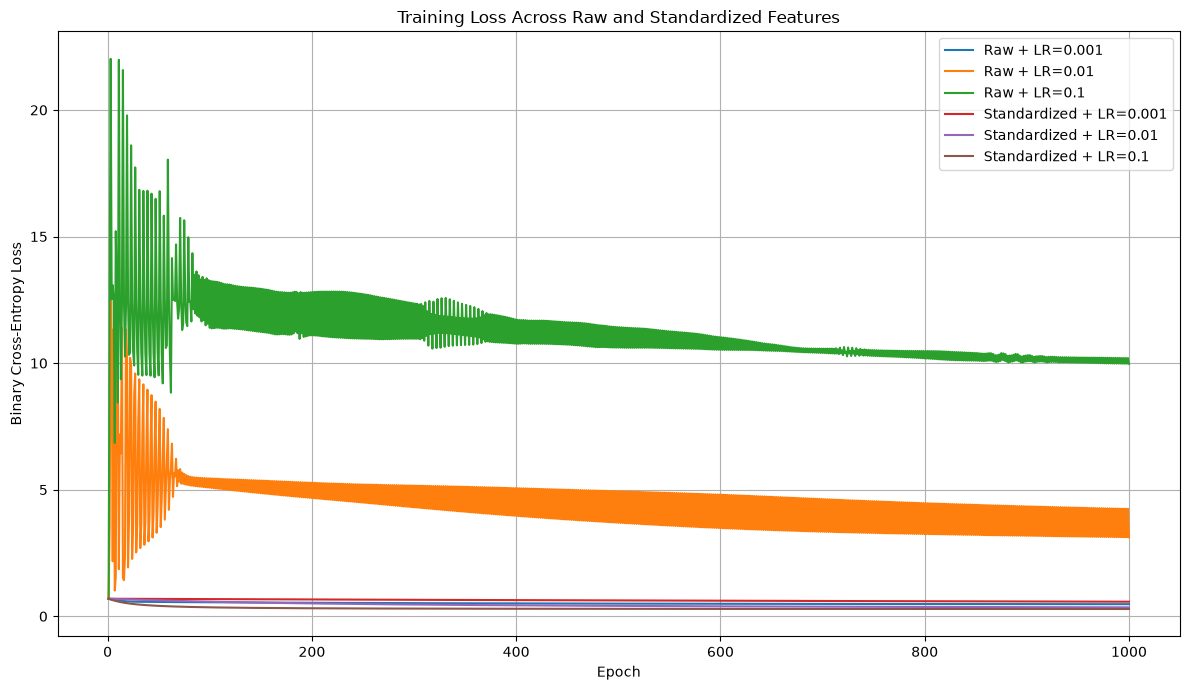

Saved: d:\churnlab\loss_curves.png


In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for r in results:
    label = f"{r['Features']} + LR={r['Learning Rate']}"
    plt.plot(
        range(1, len(r["Loss History"]) + 1),
        r["Loss History"],
        label=label
    )

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss Across Raw and Standardized Features")
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_curve_path = PROJECT_ROOT / "loss_curves.png"
plt.savefig(loss_curve_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", loss_curve_path)

## 9. Convergence Speed

The convergence criterion is defined as the first epoch at which training Binary Cross-Entropy loss becomes less than 0.30. If the threshold is not reached within 1000 epochs, the result is recorded as "Not reached".

In [43]:
convergence_df = results_df[
    ["Features", "Learning Rate", "Convergence Epoch"]
].copy()

convergence_df["Experiment"] = (
    convergence_df["Features"]
    + " + LR="
    + convergence_df["Learning Rate"].astype(str)
)

convergence_df[["Experiment", "Convergence Epoch"]]

,Experiment,Convergence Epoch
0,Raw + LR=0.001,NaN
1,Raw + LR=0.01,NaN
2,Raw + LR=0.1,NaN
3,Standardized + LR=0.001,NaN
4,Standardized + LR=0.01,NaN
5,Standardized + LR=0.1,351.0


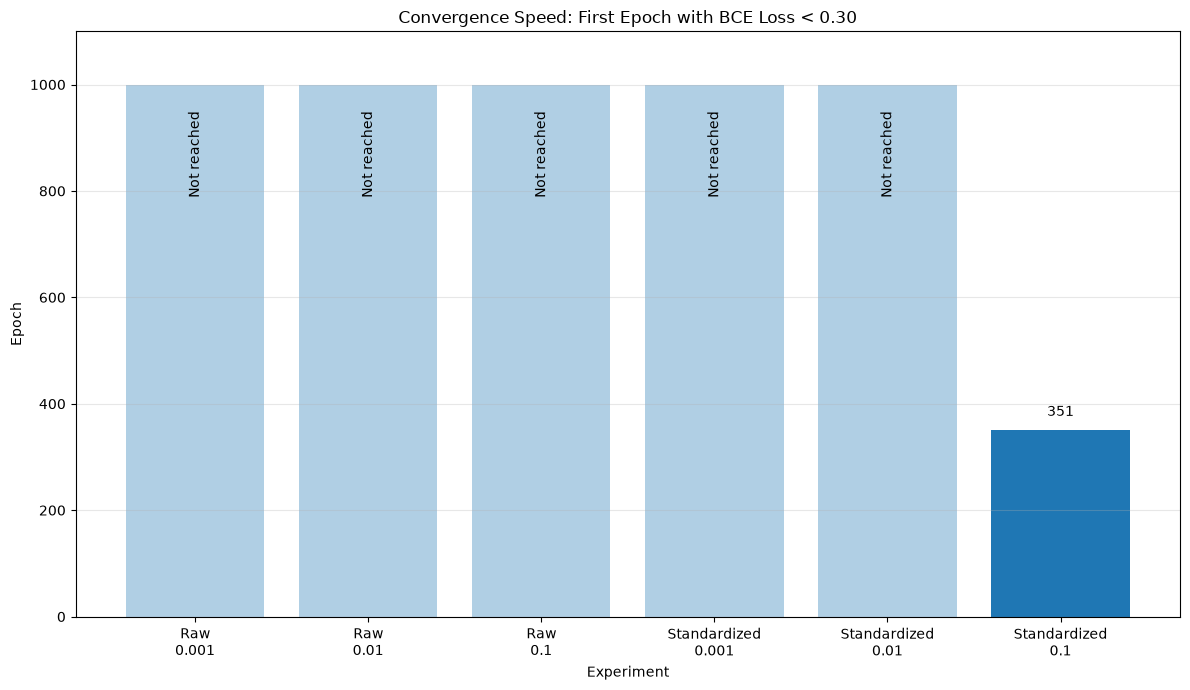

Saved: d:\churnlab\convergence_speed.png


In [44]:
import matplotlib.pyplot as plt
import numpy as np

experiments = [
    "Raw\n0.001",
    "Raw\n0.01",
    "Raw\n0.1",
    "Standardized\n0.001",
    "Standardized\n0.01",
    "Standardized\n0.1"
]

convergence_values = [1000, 1000, 1000, 1000, 1000, 351]
not_reached = [True, True, True, True, True, False]

x = np.arange(len(experiments))

plt.figure(figsize=(12, 7))

bars = plt.bar(x, convergence_values)

for i, bar in enumerate(bars):
    if not_reached[i]:
        bar.set_alpha(0.35)
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            950,
            "Not reached",
            ha="center",
            va="top",
            rotation=90
        )
    else:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            convergence_values[i] + 20,
            "351",
            ha="center",
            va="bottom"
        )

plt.xticks(x, experiments)
plt.xlabel("Experiment")
plt.ylabel("Epoch")
plt.title("Convergence Speed: First Epoch with BCE Loss < 0.30")

plt.ylim(0, 1100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

convergence_path = PROJECT_ROOT / "convergence_speed.png"
plt.savefig(convergence_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", convergence_path)

## 10. F1-Score Comparison

The F1-score is compared across all six experimental conditions using the same held-out test set.

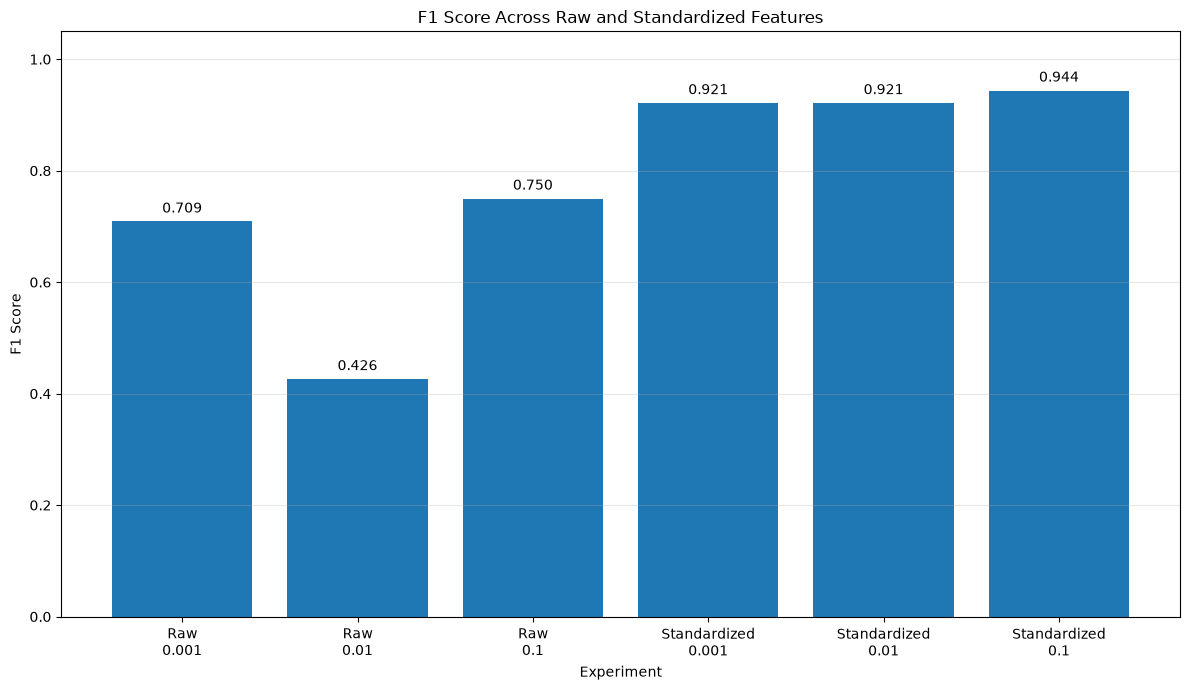

Saved: d:\churnlab\f1_scores.png


In [45]:
import matplotlib.pyplot as plt
import numpy as np

experiments = [
    "Raw\n0.001",
    "Raw\n0.01",
    "Raw\n0.1",
    "Standardized\n0.001",
    "Standardized\n0.01",
    "Standardized\n0.1"
]

f1_values = results_df["F1 Score"].to_numpy()

x = np.arange(len(experiments))

plt.figure(figsize=(12, 7))

bars = plt.bar(x, f1_values)

for bar, value in zip(bars, f1_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.xticks(x, experiments)
plt.xlabel("Experiment")
plt.ylabel("F1 Score")
plt.title("F1 Score Across Raw and Standardized Features")

plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

f1_path = PROJECT_ROOT / "f1_scores.png"
plt.savefig(f1_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", f1_path)

In [46]:
final_results = results_df.copy()

# Replace pandas NaN with the research wording
final_results["Convergence Epoch"] = final_results["Convergence Epoch"].apply(
    lambda x: "Not reached" if pd.isna(x) else int(x)
)

# Round values for presentation
final_results["Final Loss"] = final_results["Final Loss"].round(6)
final_results["Accuracy"] = final_results["Accuracy"].round(6)
final_results["F1 Score"] = final_results["F1 Score"].round(6)

final_results

,Features,Learning Rate,Final Loss,Convergence Epoch,Accuracy,F1 Score
0,Raw,0.001,0.478659,Not reached,0.77,0.708861
1,Raw,0.010,3.121533,Not reached,0.65,0.426230
2,Raw,0.100,9.974895,Not reached,0.72,0.750000
3,Standardized,0.001,0.576303,Not reached,0.93,0.921348
4,Standardized,0.010,0.353678,Not reached,0.93,0.921348
5,Standardized,0.100,0.288547,351,0.95,0.943820


In [48]:
final_results_path = PROJECT_ROOT / "experiment_results.csv"

final_results.to_csv(
    final_results_path,
    index=False
)

print("Saved:", final_results_path)

Saved: d:\churnlab\experiment_results.csv


In [50]:
converged = final_results[
    final_results["Convergence Epoch"] != "Not reached"
]

print(converged)

       Features  Learning Rate  Final Loss Convergence Epoch  Accuracy  \
5  Standardized            0.1    0.288547               351      0.95   

   F1 Score  
5   0.94382  
